In [1]:
import os, getpass
os.environ["KGAT_bc3221da7167f9aaa168a77f275194d9"] = getpass.getpass("Paste your Kaggle token: ")

Paste your Kaggle token: ··········


In [2]:
!pip install -q --upgrade kaggle
!kaggle competitions download -c home-credit-default-risk -f application_train.csv
!kaggle competitions download -c home-credit-default-risk -f bureau.csv
!for f in *.zip; do unzip -o "$f"; done

Authentication required to call the Kaggle API.

First, you will need a Kaggle account. You can sign up at
  https://www.kaggle.com/account/login

Recommended: log in with OAuth via a web-based authorization flow.
No token to manage; credentials are cached locally for you.
    kaggle auth login

If you'd rather not use OAuth, generate an API token at
  https://www.kaggle.com/settings/api  (click "Generate New Token" under "API")
and supply it to the CLI in one of these ways:

  Option A: Environment variable
    export KAGGLE_API_TOKEN=xxxxxxxxxxxxxx  # token copied from the settings UI

  Option B: API token file
    Save the token to ~/.kaggle/access_token
Authentication required to call the Kaggle API.

First, you will need a Kaggle account. You can sign up at
  https://www.kaggle.com/account/login

Recommended: log in with OAuth via a web-based authorization flow.
No token to manage; credentials are cached locally for you.
    kaggle auth login

If you'd rather not use OAuth, gener

In [3]:
!ls -l application_train.csv bureau.csv
!wc -l application_train.csv

ls: cannot access 'application_train.csv': No such file or directory
ls: cannot access 'bureau.csv': No such file or directory
wc: application_train.csv: No such file or directory


In [4]:
import numpy as np, pandas as pd

app = pd.read_csv("/content/drive/MyDrive/credit_risk_data/application_train.csv")
bureau = pd.read_csv("/content/drive/MyDrive/credit_risk_data/bureau.csv")
n0 = len(app)
print("application:", app.shape, "| bureau:", bureau.shape)

# 1. Who carries the 365243 placeholder?
bad = app["DAYS_EMPLOYED"] == 365243
print("\nPlaceholder rows by income type:")
print(app.loc[bad, "NAME_INCOME_TYPE"].value_counts())
print("\nOther rows by income type (top 6):")
print(app.loc[~bad, "NAME_INCOME_TYPE"].value_counts().head(6))

# 2. Cleaning
app["DAYS_EMPLOYED_PLACEHOLDER"] = bad.astype(int)
app.loc[bad, "DAYS_EMPLOYED"] = np.nan
app["AGE_YEARS"] = -app["DAYS_BIRTH"] / 365.25
app["EMPLOYED_YEARS"] = -app["DAYS_EMPLOYED"] / 365.25
app = app.drop(columns=["DAYS_BIRTH", "DAYS_EMPLOYED"])
for c in ["CODE_GENDER", "ORGANIZATION_TYPE"]:
    app[c] = app[c].replace("XNA", np.nan)

# ratios first, then log-transform the skewed money columns
app["CREDIT_INCOME_RATIO"] = app["AMT_CREDIT"] / app["AMT_INCOME_TOTAL"]
app["ANNUITY_INCOME_RATIO"] = app["AMT_ANNUITY"] / app["AMT_INCOME_TOTAL"]
for c in ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE"]:
    app[c] = np.log1p(app[c])

# 3. Bureau: one row per applicant
b = bureau.copy()
b["IS_ACTIVE"] = (b["CREDIT_ACTIVE"] == "Active").astype(int)
b["HAS_OVERDUE"] = (b["CREDIT_DAY_OVERDUE"] > 0).astype(int)
agg = b.groupby("SK_ID_CURR").agg(
    BUREAU_N_LOANS=("SK_ID_BUREAU", "count"),
    BUREAU_N_ACTIVE=("IS_ACTIVE", "sum"),
    BUREAU_N_OVERDUE=("HAS_OVERDUE", "sum"),
    BUREAU_MAX_OVERDUE_DAYS=("CREDIT_DAY_OVERDUE", "max"),
    BUREAU_CREDIT_SUM_MEAN=("AMT_CREDIT_SUM", "mean"),
    BUREAU_DEBT_SUM=("AMT_CREDIT_SUM_DEBT", "sum"),
    BUREAU_DAYS_CREDIT_MEAN=("DAYS_CREDIT", "mean"),
).reset_index()

app = app.merge(agg, on="SK_ID_CURR", how="left")
assert len(app) == n0 and app["SK_ID_CURR"].is_unique, "join duplicated rows"
app["HAS_BUREAU"] = app["BUREAU_N_LOANS"].notna().astype(int)
for c in ["BUREAU_N_LOANS", "BUREAU_N_ACTIVE", "BUREAU_N_OVERDUE"]:
    app[c] = app[c].fillna(0)
print("\nApplicants with no bureau record:", (app["HAS_BUREAU"] == 0).sum())
print(app.groupby("HAS_BUREAU")["TARGET"].agg(["mean", "count"]))

# 4. Drop columns that are more than 50% missing
miss = app.isna().mean()
drop = miss[miss > 0.5].index.tolist()
print("\nDropping", len(drop), "columns with >50% missing")
app = app.drop(columns=drop)
print("Final shape:", app.shape)
app.to_parquet("clean.parquet")

application: (307511, 122) | bureau: (1716428, 17)

Placeholder rows by income type:
NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22
Name: count, dtype: int64

Other rows by income type (top 6):
NAME_INCOME_TYPE
Working                 158774
Commercial associate     71617
State servant            21703
Student                     18
Pensioner                   10
Businessman                 10
Name: count, dtype: int64

Applicants with no bureau record: 44020
                mean   count
HAS_BUREAU                  
0           0.101249   44020
1           0.077301  263491

Dropping 41 columns with >50% missing
Final shape: (307511, 92)


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

y = app["TARGET"].values
X = app.drop(columns=["TARGET", "SK_ID_CURR"])
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=42)
X_cal, X_te, y_cal, y_te = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=42)
print("split sizes:", len(y_tr), len(y_cal), len(y_te))
print("default rate:", y_tr.mean().round(4), y_cal.mean().round(4), y_te.mean().round(4))

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("numeric cols:", len(num_cols), "| categorical cols:", len(cat_cols))

pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="missing")),
                      ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=100,
                                           sparse_output=False))]), cat_cols),
])

# fit on train only, so nothing leaks from calibration or test
Xt_tr = pre.fit_transform(X_tr).astype(np.float32)
Xt_cal = pre.transform(X_cal).astype(np.float32)
Xt_te = pre.transform(X_te).astype(np.float32)
feat_names = pre.get_feature_names_out()
print("matrix shape:", Xt_tr.shape, "| NaNs left:", int(np.isnan(Xt_tr).sum()))
np.savez_compressed("processed.npz", Xt_tr=Xt_tr, Xt_cal=Xt_cal, Xt_te=Xt_te,
                    y_tr=y_tr, y_cal=y_cal, y_te=y_te)

split sizes: 184506 61502 61503
default rate: 0.0807 0.0807 0.0807
numeric cols: 77 | categorical cols: 13
matrix shape: (184506, 197) | NaNs left: 0


logistic regression fitted in 7 s, iterations: [53]
xgboost fitted in 53 s

TEST SET RESULTS
                model    AUC  log_loss  brier    ECE
constant (prevalence) 0.5000    0.2805 0.0742 0.0023
  logistic regression 0.7540    0.2476 0.0681 0.0026
              xgboost 0.7613    0.2450 0.0675 0.0034
accuracy of 'nobody defaults': 0.9193

Reliability, logistic regression (10 equal-count bins)
 mean_predicted  observed_rate      n
         0.0128         0.0140 6151.0
         0.0222         0.0213 6151.0
         0.0304         0.0254 6151.0
         0.0393         0.0354 6150.0
         0.0496         0.0476 6150.0
         0.0622         0.0662 6150.0
         0.0791         0.0803 6150.0
         0.1036         0.1047 6150.0
         0.1440         0.1454 6150.0
         0.2617         0.2670 6150.0

Reliability, xgboost (10 equal-count bins)
 mean_predicted  observed_rate      n
         0.0136         0.0127 6151.0
         0.0224         0.0169 6151.0
         0.0300         0

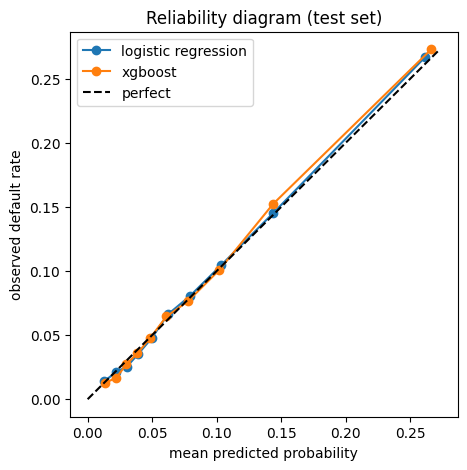


LR most negative coefficients:
 num__AMT_GOODS_PRICE                   -1.113
cat__CODE_GENDER_F                     -0.475
cat__ORGANIZATION_TYPE_Military        -0.471
num__EXT_SOURCE_3                      -0.435
cat__FLAG_OWN_CAR_Y                    -0.425
cat__NAME_CONTRACT_TYPE_Cash loans     -0.414
num__EXT_SOURCE_2                      -0.388
cat__ORGANIZATION_TYPE_Trade: type 2   -0.382
dtype: float64

LR most positive coefficients:
 num__FLAG_DOCUMENT_3                        0.180
cat__ORGANIZATION_TYPE_Industry: type 1     0.185
num__BUREAU_N_ACTIVE                        0.201
cat__ORGANIZATION_TYPE_Construction         0.260
cat__ORGANIZATION_TYPE_Realtor              0.272
cat__OCCUPATION_TYPE_Low-skill Laborers     0.278
cat__ORGANIZATION_TYPE_Transport: type 3    0.496
num__AMT_CREDIT                             1.272
dtype: float64

XGBoost top 10 features:
 num__EXT_SOURCE_3                                         0.0560
num__EXT_SOURCE_2                           

In [6]:
import time, matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss

t = time.time()
lr = LogisticRegression(C=1.0, max_iter=2000)
lr.fit(Xt_tr, y_tr)
print("logistic regression fitted in", round(time.time() - t), "s, iterations:", lr.n_iter_)

t = time.time()
xgb = XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8,
                    colsample_bytree=0.8, min_child_weight=5, tree_method="hist",
                    n_jobs=-1, random_state=42, eval_metric="logloss")
xgb.fit(Xt_tr, y_tr)
print("xgboost fitted in", round(time.time() - t), "s")

def ece_quantile(y, p, n_bins=10):
    o = np.argsort(p); y, p = y[o], p[o]
    return sum(len(i) / len(p) * abs(p[i].mean() - y[i].mean())
               for i in np.array_split(np.arange(len(p)), n_bins))

def reliability(y, p, n_bins=10):
    o = np.argsort(p); y, p = y[o], p[o]
    return np.array([[p[i].mean(), y[i].mean(), len(i)] for i in np.array_split(np.arange(len(p)), n_bins)])

p_const = np.full(len(y_te), y_tr.mean())
preds = {"constant (prevalence)": p_const,
         "logistic regression": lr.predict_proba(Xt_te)[:, 1],
         "xgboost": xgb.predict_proba(Xt_te)[:, 1]}

rows = []
for name, p in preds.items():
    rows.append([name, roc_auc_score(y_te, p), log_loss(y_te, p),
                 brier_score_loss(y_te, p), ece_quantile(y_te, p)])
res = pd.DataFrame(rows, columns=["model", "AUC", "log_loss", "brier", "ECE"]).round(4)
print("\nTEST SET RESULTS")
print(res.to_string(index=False))
print("accuracy of 'nobody defaults':", round((y_te == 0).mean(), 4))

for name in ["logistic regression", "xgboost"]:
    r = reliability(y_te, preds[name])
    print("\nReliability,", name, "(10 equal-count bins)")
    print(pd.DataFrame(r, columns=["mean_predicted", "observed_rate", "n"]).round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(5, 5))
m = 0.0
for name in ["logistic regression", "xgboost"]:
    r = reliability(y_te, preds[name]); m = max(m, r[:, 0].max(), r[:, 1].max())
    ax.plot(r[:, 0], r[:, 1], "o-", label=name)
ax.plot([0, m], [0, m], "k--", label="perfect")
ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed default rate")
ax.legend(); ax.set_title("Reliability diagram (test set)")
plt.savefig("reliability_baseline.png", dpi=150, bbox_inches="tight"); plt.show()

coef = pd.Series(lr.coef_[0], index=feat_names).sort_values()
print("\nLR most negative coefficients:\n", coef.head(8).round(3))
print("\nLR most positive coefficients:\n", coef.tail(8).round(3))
imp = pd.Series(xgb.feature_importances_, index=feat_names).sort_values(ascending=False)
print("\nXGBoost top 10 features:\n", imp.head(10).round(4))

corr(AMT_CREDIT, AMT_GOODS_PRICE): 0.9882
smallest eigenvalues: [-3.17296224e-15 -3.02689043e-16 -2.09319925e-16 -1.42446072e-16
 -6.72950511e-17]
largest eigenvalue: 6.35
numerical rank: 183 of 197

SUBGROUP CALIBRATION
                group model     n  observed  mean_pred    AUC
             gender F    LR 40345    0.0696     0.0701 0.7492
             gender F   XGB 40345    0.0696     0.0706 0.7558
             gender M    LR 21158    0.1020     0.1003 0.7472
             gender M   XGB 21158    0.1020     0.0991 0.7563
pensioner placeholder    LR 11028    0.0524     0.0547 0.7200
pensioner placeholder   XGB 11028    0.0524     0.0536 0.7308
     no bureau record    LR  8935    0.0989     0.1029 0.7213
     no bureau record   XGB  8935    0.0989     0.1018 0.7365
    has bureau record    LR 52568    0.0776     0.0767 0.7590
    has bureau record   XGB 52568    0.0776     0.0767 0.7646

Platt parameters (slope, intercept): 0.978 -2.432

CLASS WEIGHTING EXPERIMENT (test set; true de

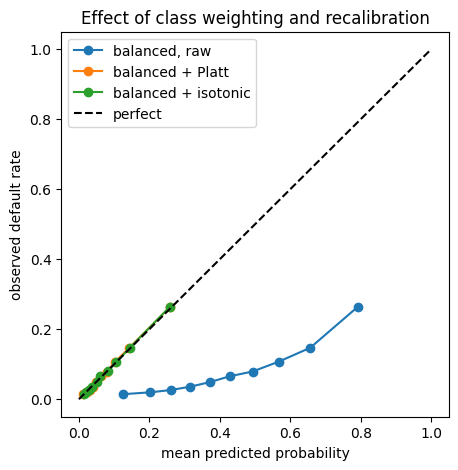

In [7]:
from sklearn.isotonic import IsotonicRegression

# 1. Collinearity: how singular is X'X?
fn = list(feat_names)
i_c, i_g = fn.index("num__AMT_CREDIT"), fn.index("num__AMT_GOODS_PRICE")
print("corr(AMT_CREDIT, AMT_GOODS_PRICE):", np.corrcoef(Xt_tr[:, i_c], Xt_tr[:, i_g])[0, 1].round(4))
Xd = Xt_tr.astype(np.float64)
G = Xd.T @ Xd / len(Xd)
ev = np.linalg.eigvalsh(G)
print("smallest eigenvalues:", ev[:5])
print("largest eigenvalue:", ev[-1].round(2))
print("numerical rank:", np.linalg.matrix_rank(G), "of", G.shape[0])

# 2. Subgroup calibration (test set)
groups = {
    "gender F": (X_te["CODE_GENDER"] == "F").values,
    "gender M": (X_te["CODE_GENDER"] == "M").values,
    "pensioner placeholder": (X_te["DAYS_EMPLOYED_PLACEHOLDER"] == 1).values,
    "no bureau record": (X_te["HAS_BUREAU"] == 0).values,
    "has bureau record": (X_te["HAS_BUREAU"] == 1).values,
}
rows = []
for g, m in groups.items():
    for name, p in [("LR", preds["logistic regression"]), ("XGB", preds["xgboost"])]:
        rows.append([g, name, int(m.sum()), y_te[m].mean(), p[m].mean(), roc_auc_score(y_te[m], p[m])])
print("\nSUBGROUP CALIBRATION")
print(pd.DataFrame(rows, columns=["group", "model", "n", "observed", "mean_pred", "AUC"]).round(4).to_string(index=False))

# 3. Class weighting breaks probabilities, recalibration repairs them
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

def evaluate(name, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return [name, roc_auc_score(y_te, p), log_loss(y_te, p), brier_score_loss(y_te, p),
            ece_quantile(y_te, p), p.mean()]

lr_bal = LogisticRegression(C=1.0, max_iter=2000, class_weight="balanced").fit(Xt_tr, y_tr)
s_cal = lr_bal.predict_proba(Xt_cal)[:, 1]
s_te = lr_bal.predict_proba(Xt_te)[:, 1]

platt = LogisticRegression(C=1e6, max_iter=1000).fit(logit(s_cal).reshape(-1, 1), y_cal)
p_platt = platt.predict_proba(logit(s_te).reshape(-1, 1))[:, 1]
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(s_cal, y_cal)
p_iso = iso.predict(s_te)
print("\nPlatt parameters (slope, intercept):", platt.coef_[0][0].round(3), platt.intercept_[0].round(3))

rows = [evaluate("LR (no weighting)", preds["logistic regression"]),
        evaluate("LR balanced, raw", s_te),
        evaluate("LR balanced + Platt", p_platt),
        evaluate("LR balanced + isotonic", p_iso)]
print("\nCLASS WEIGHTING EXPERIMENT (test set; true default rate = %.4f)" % y_te.mean())
print(pd.DataFrame(rows, columns=["model", "AUC", "log_loss", "brier", "ECE", "mean_pred"]).round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(5, 5))
for name, p in [("balanced, raw", s_te), ("balanced + Platt", p_platt), ("balanced + isotonic", p_iso)]:
    r = reliability(y_te, p)
    ax.plot(r[:, 0], r[:, 1], "o-", label=name)
ax.plot([0, 1], [0, 1], "k--", label="perfect")
ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed default rate")
ax.legend(); ax.set_title("Effect of class weighting and recalibration")
plt.savefig("reliability_balanced.png", dpi=150, bbox_inches="tight"); plt.show()

In [8]:
import xgboost as xgbmod
from scipy.linalg import qr

# 1. Which columns are exactly redundant?
_, R, piv = qr(Xd[:50000], mode="economic", pivoting=True)
d = np.abs(np.diag(R))
rank = int((d > d[0] * 1e-10).sum())
print("rank on 50k rows:", rank, "of", Xd.shape[1])
print("redundant columns:", [fn[i] for i in piv[rank:]])

# 2. Gender-blind models
keep = [i for i, f in enumerate(fn) if "CODE_GENDER" not in f]
lr_ng = LogisticRegression(C=1.0, max_iter=2000).fit(Xt_tr[:, keep], y_tr)
p_lr_ng = lr_ng.predict_proba(Xt_te[:, keep])[:, 1]
xgb_ng = XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8,
                       colsample_bytree=0.8, min_child_weight=5, tree_method="hist",
                       n_jobs=-1, random_state=42, eval_metric="logloss").fit(Xt_tr[:, keep], y_tr)
p_xgb_ng = xgb_ng.predict_proba(Xt_te[:, keep])[:, 1]
rows = [evaluate("LR with gender", preds["logistic regression"]), evaluate("LR without gender", p_lr_ng),
        evaluate("XGB with gender", preds["xgboost"]), evaluate("XGB without gender", p_xgb_ng)]
print("\nGENDER ABLATION")
print(pd.DataFrame(rows, columns=["model", "AUC", "log_loss", "brier", "ECE", "mean_pred"]).round(4).to_string(index=False))
mF, mM = groups["gender F"], groups["gender M"]
print("observed F/M:", y_te[mF].mean().round(4), y_te[mM].mean().round(4))
for name, p in [("LR without gender", p_lr_ng), ("XGB without gender", p_xgb_ng)]:
    print(name, "mean predicted F/M:", p[mF].mean().round(4), p[mM].mean().round(4))

# 3. Coefficient instability from two near-identical columns
dropi = fn.index("num__AMT_GOODS_PRICE")
keep2 = [i for i in range(len(fn)) if i != dropi]
lr2 = LogisticRegression(C=1.0, max_iter=2000).fit(Xt_tr[:, keep2], y_tr)
j = [fn[i] for i in keep2].index("num__AMT_CREDIT")
print("\nAMT_CREDIT coefficient with goods price:", lr.coef_[0][fn.index("num__AMT_CREDIT")].round(3),
      "| without:", lr2.coef_[0][j].round(3))
print("AUC without AMT_GOODS_PRICE:", roc_auc_score(y_te, lr2.predict_proba(Xt_te[:, keep2])[:, 1]).round(4))

# 4. TreeSHAP from XGBoost, 5,000 test rows
idx = np.random.RandomState(0).choice(len(Xt_te), 5000, replace=False)
contrib = xgb.get_booster().predict(xgbmod.DMatrix(Xt_te[idx]), pred_contribs=True)
sv = contrib[:, :-1]
print("\nSHAP additivity check (should be ~0):",
      np.abs(contrib.sum(axis=1) - xgb.get_booster().predict(xgbmod.DMatrix(Xt_te[idx]), output_margin=True)).max().round(5))
shap_rank = pd.Series(np.abs(sv).mean(axis=0), index=feat_names).sort_values(ascending=False)
print("\nTop 10 by mean |SHAP|:\n", shap_rank.head(10).round(4))
print("\nTop 10 by XGBoost gain importance:\n", imp.head(10).round(4))

rank on 50k rows: 180 of 197
redundant columns: ['cat__ORGANIZATION_TYPE_Transport: type 1', 'cat__FLAG_OWN_CAR_Y', 'cat__NAME_CONTRACT_TYPE_Revolving loans', 'cat__WEEKDAY_APPR_PROCESS_START_SUNDAY', 'cat__NAME_TYPE_SUITE_Group of people', 'cat__EMERGENCYSTATE_MODE_Yes', 'cat__NAME_HOUSING_TYPE_Co-op apartment', 'cat__OCCUPATION_TYPE_HR staff', 'cat__NAME_INCOME_TYPE_infrequent_sklearn', 'cat__NAME_EDUCATION_TYPE_infrequent_sklearn', 'cat__FLAG_OWN_REALTY_N', 'cat__NAME_FAMILY_STATUS_Widow', 'cat__ORGANIZATION_TYPE_missing', 'num__FLAG_MOBIL', 'num__FLAG_DOCUMENT_12', 'cat__CODE_GENDER_infrequent_sklearn', 'cat__NAME_FAMILY_STATUS_infrequent_sklearn']

GENDER ABLATION
             model    AUC  log_loss  brier    ECE  mean_pred
    LR with gender 0.7540    0.2476 0.0681 0.0026     0.0805
 LR without gender 0.7512    0.2483 0.0683 0.0036     0.0804
   XGB with gender 0.7613    0.2450 0.0675 0.0034     0.0804
XGB without gender 0.7587    0.2457 0.0676 0.0040     0.0804
observed F/M: 0.0

table: (184506, 198)

NEWTON'S METHOD
iter  1: objective = 0.29282931   size of slope before the step = 1.13e+00
iter  2: objective = 0.25497588   size of slope before the step = 2.20e-01
iter  3: objective = 0.24920980   size of slope before the step = 5.59e-02
iter  4: objective = 0.24890647   size of slope before the step = 1.06e-02
iter  5: objective = 0.24890455   size of slope before the step = 6.75e-04
iter  6: objective = 0.24890440   size of slope before the step = 2.39e-05
iter  7: objective = 0.24890434   size of slope before the step = 8.51e-06
iter  8: objective = 0.24890432   size of slope before the step = 3.04e-06
iter  9: objective = 0.24890432   size of slope before the step = 1.02e-06
iter 10: objective = 0.24890432   size of slope before the step = 2.82e-07
iter 11: objective = 0.24890432   size of slope before the step = 4.53e-08
iter 12: objective = 0.24890432   size of slope before the step = 1.79e-09
iter 13: objective = 0.24890432   size of slope before the ste

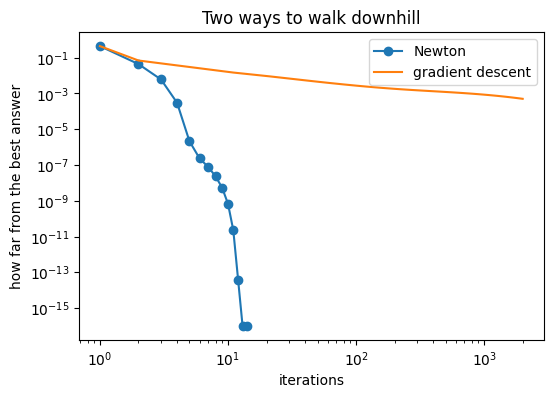

In [9]:
import numpy as np, pandas as pd, time
import matplotlib.pyplot as plt
from scipy.special import expit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss

# make sure the data is in memory (reload it if Colab was reset)
try:
    Xt_tr
except NameError:
    d = np.load("processed.npz")
    Xt_tr, Xt_te, y_tr, y_te = d["Xt_tr"], d["Xt_te"], d["y_tr"], d["y_te"]

# add a column of ones at the end, so the intercept b becomes just one more number in theta
A  = np.hstack([Xt_tr.astype(np.float64), np.ones((len(Xt_tr), 1))])
At = np.hstack([Xt_te.astype(np.float64), np.ones((len(Xt_te), 1))])
y = y_tr.astype(np.float64)
n, d1 = A.shape
print("table:", A.shape)

# a small penalty, the same one scikit-learn uses by default (C = 1); it is not applied to the intercept
lam = 1.0 / n
pen = np.full(d1, lam); pen[-1] = 0.0

def objective(theta):
    z = A @ theta
    return np.mean(np.logaddexp(0, z) - y * z) + 0.5 * np.sum(pen * theta**2)   # average loss + penalty

def gradient(theta):
    p = expit(A @ theta)
    return A.T @ (p - y) / n + pen * theta     # the formula we derived: (p - y) times x, averaged

# ---------- Newton's method ----------
theta = np.zeros(d1)
newton_obj = [objective(theta)]
print("\nNEWTON'S METHOD")
t0 = time.time()
for it in range(1, 16):
    p = expit(A @ theta)
    g = A.T @ (p - y) / n + pen * theta
    W = p * (1 - p)
    H = (A * W[:, None]).T @ A / n + np.diag(pen)     # how the slope itself bends (the Hessian)
    theta = theta - np.linalg.solve(H, g)
    newton_obj.append(objective(theta))
    print(f"iter {it:2d}: objective = {newton_obj[-1]:.8f}   size of slope before the step = {np.linalg.norm(g):.2e}")
    if np.linalg.norm(g) < 1e-9:
        break
print("time:", round(time.time() - t0), "s")
theta_newton = theta.copy()
best = objective(theta_newton)

# what the penalty does to the redundant columns we found earlier
p = expit(A @ theta_newton); W = p * (1 - p)
H0 = (A * W[:, None]).T @ A / n
print("\nsmallest eigenvalue WITHOUT penalty:", np.linalg.eigvalsh(H0)[0])
print("smallest eigenvalue WITH penalty:   ", np.linalg.eigvalsh(H0 + np.diag(pen))[0])

# ---------- gradient descent (the same walk downhill as the 5-student example) ----------
th = np.zeros(d1)
gd_steps, gd_gaps = [0], [objective(th) - best]
print("\nGRADIENT DESCENT")
t0 = time.time()
for it in range(1, 2001):
    th = th - 0.5 * gradient(th)
    if it % 20 == 0 or it in (1, 10, 50):
        gd_steps.append(it); gd_gaps.append(objective(th) - best)
    if it in (1, 10, 50, 100, 500, 1000, 2000):
        print(f"step {it:5d}: objective gap to the best = {objective(th) - best:.2e}")
print("time:", round(time.time() - t0), "s")

# ---------- compare with scikit-learn on the test set ----------
sk = LogisticRegression(C=1.0, max_iter=5000).fit(Xt_tr, y_tr)
sk_theta = np.r_[sk.coef_[0], sk.intercept_[0]]
p_sk = sk.predict_proba(Xt_te)[:, 1]
print("\nscikit-learn objective gap to our best:", f"{objective(sk_theta) - best:.2e}")

rows = []
for name, th_ in [("scikit-learn", sk_theta), ("our Newton", theta_newton), ("our gradient descent", th)]:
    pr = expit(At @ th_)
    rows.append([name, roc_auc_score(y_te, pr), log_loss(y_te, pr),
                 np.abs(pr - p_sk).max(), np.abs(th_ - sk_theta).max()])
print(pd.DataFrame(rows, columns=["method", "test AUC", "test log-loss",
      "max diff in percentages vs sklearn", "max diff in coefficients vs sklearn"]).round(5).to_string(index=False))

# ---------- picture ----------
gaps_newton = np.maximum(np.array(newton_obj) - best, 1e-16)
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(np.arange(len(gaps_newton)) + 1, gaps_newton, "o-", label="Newton")
ax.loglog(np.array(gd_steps) + 1, np.maximum(gd_gaps, 1e-16), label="gradient descent")
ax.set_xlabel("iterations"); ax.set_ylabel("how far from the best answer")
ax.legend(); ax.set_title("Two ways to walk downhill")
plt.savefig("newton_vs_gd.png", dpi=150, bbox_inches="tight"); plt.show()

In [10]:
# 1. how big was the slope at scikit-learn's answer vs ours?
print("slope size at sklearn answer:", f"{np.linalg.norm(gradient(sk_theta)):.2e}")
print("slope size at our Newton answer:", f"{np.linalg.norm(gradient(theta_newton)):.2e}")

# 2. which coefficients differ most, and how many applicants are affected?
names = list(feat_names) + ["intercept"]
diff = np.abs(sk_theta - theta_newton)
for j in np.argsort(-diff)[:5]:
    print(f"{names[j]:45s} sklearn {sk_theta[j]:9.3f}   ours {theta_newton[j]:9.3f}")
p_newton = expit(At @ theta_newton)
print("share of test applicants whose percentage differs by more than 0.01:",
      (np.abs(p_sk - p_newton) > 0.01).mean().round(5))

# 3. rerun scikit-learn with a tighter stopping rule (this solver is Newton's method too)
sk2 = LogisticRegression(C=1.0, solver="newton-cholesky", tol=1e-12, max_iter=100).fit(A[:, :-1], y_tr)
th2 = np.r_[sk2.coef_[0], sk2.intercept_[0]]
p2 = sk2.predict_proba(At[:, :-1])[:, 1]
print("\nobjective gap to our best:", f"{objective(th2) - best:.2e}")
print("max diff in coefficients vs our Newton:", np.abs(th2 - theta_newton).max().round(6))
print("max diff in percentages vs our Newton: ", np.abs(p2 - p_newton).max().round(6))


slope size at sklearn answer: 3.45e-04
slope size at our Newton answer: 4.45e-17
intercept                                     sklearn    -0.610   ours    -3.191
cat__NAME_INCOME_TYPE_Pensioner               sklearn    -0.186   ours    -1.292
cat__NAME_EDUCATION_TYPE_infrequent_sklearn   sklearn    -0.140   ours    -1.108
cat__ORGANIZATION_TYPE_Legal Services         sklearn     0.179   ours     0.831
cat__NAME_INCOME_TYPE_State servant           sklearn    -0.217   ours     0.317
share of test applicants whose percentage differs by more than 0.01: 0.01257

objective gap to our best: 0.00e+00
max diff in coefficients vs our Newton: 0.0
max diff in percentages vs our Newton:  0.0


In [11]:
print("test AUC:", round(roc_auc_score(y_te, p2), 5), " test log-loss:", round(log_loss(y_te, p2), 5))

test AUC: 0.75355  test log-loss: 0.24764


In [12]:
%%writefile logreg.py
"""Logistic regression built from scratch with Newton's method.

Model: chance of default p = 1 / (1 + exp(-(A @ theta)))
Loss : average log-loss (optionally weighted) plus a small L2 penalty
"""
import numpy as np
from scipy.special import expit


def objective(theta, A, y, sw, pen):
    z = A @ theta
    return np.mean(sw * (np.logaddexp(0, z) - y * z)) + 0.5 * np.sum(pen * theta ** 2)


def gradient(theta, A, y, sw, pen):
    # the formula we derived: (p - y) times x, averaged, plus the penalty's slope
    p = expit(A @ theta)
    return A.T @ (sw * (p - y)) / len(y) + pen * theta


def hessian(theta, A, sw, pen):
    # how the slope itself bends: average of p(1-p) times x times x-transpose
    p = expit(A @ theta)
    W = sw * p * (1 - p)
    return (A * W[:, None]).T @ A / len(A) + np.diag(pen)


def fit_newton(A, y, sample_weight=None, penalty=None, theta0=None,
               max_iter=50, tol=1e-9):
    """Returns (theta, number of Newton steps taken)."""
    n, d = A.shape
    sw = np.ones(n) if sample_weight is None else np.asarray(sample_weight, float)
    pen = np.zeros(d) if penalty is None else np.asarray(penalty, float)
    theta = np.zeros(d) if theta0 is None else np.array(theta0, float)
    steps = 0
    while steps < max_iter:
        g = gradient(theta, A, y, sw, pen)
        if np.linalg.norm(g) < tol:
            break
        theta = theta - np.linalg.solve(hessian(theta, A, sw, pen), g)
        steps += 1
    return theta, steps


def predict_proba(A, theta):
    return expit(A @ theta)

Writing logreg.py


plain model: Newton steps = 12
weight ratio defaulter / non-defaulter = 11.3871   n0/n1 = 11.3871
weighted model: Newton steps = 11

Platt (ours): slope a = 0.9778, intercept c = -2.4316  (Newton steps = 6)
algebra says: slope 1, intercept -log(n0/n1) = -2.4325

TEST SET (true default rate = 0.0807)
                         model    AUC  log_loss  brier    ECE  mean_pred
            plain model (ours) 0.7535    0.2476 0.0682 0.0026     0.0805
                 weighted, raw 0.7537    0.5901 0.2020 0.3403     0.4210
       weighted + Platt (ours) 0.7537    0.2477 0.0682 0.0030     0.0802
weighted + subtract log(n0/n1) 0.7537    0.2477 0.0682 0.0021     0.0806
           weighted + isotonic 0.7533    0.2481 0.0683 0.0022     0.0802

weighted score = 1.011 x plain score + 2.457   (algebra predicts slope 1, intercept 2.432)
correlation of the two scores: 0.9981


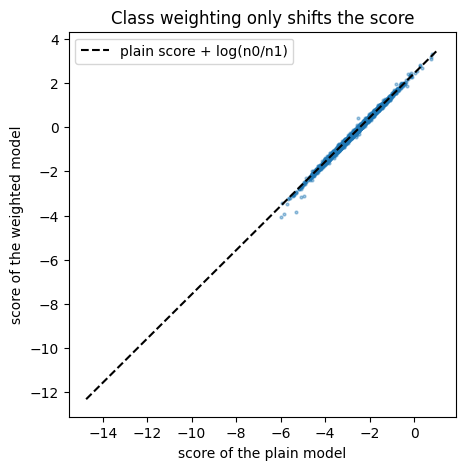

In [13]:
import numpy as np, pandas as pd, importlib
import matplotlib.pyplot as plt
from scipy.special import expit
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
from sklearn.isotonic import IsotonicRegression
import logreg; importlib.reload(logreg)
from logreg import fit_newton, predict_proba

try:
    Xt_tr
except NameError:
    d = np.load("processed.npz")
    Xt_tr, Xt_cal, Xt_te = d["Xt_tr"], d["Xt_cal"], d["Xt_te"]
    y_tr, y_cal, y_te = d["y_tr"], d["y_cal"], d["y_te"]

def add_ones(X):
    return np.hstack([X.astype(np.float64), np.ones((len(X), 1))])
A, Ac, At = add_ones(Xt_tr), add_ones(Xt_cal), add_ones(Xt_te)
y = y_tr.astype(np.float64)
n = len(y)
pen = np.full(A.shape[1], 1.0 / n); pen[-1] = 0.0     # same penalty as before, none on the intercept

def ece_quantile(yv, p, bins=10):
    o = np.argsort(p); yv, p = yv[o], p[o]
    return sum(len(i) / len(p) * abs(p[i].mean() - yv[i].mean())
               for i in np.array_split(np.arange(len(p)), bins))

def scores(name, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return [name, roc_auc_score(y_te, p), log_loss(y_te, p), brier_score_loss(y_te, p),
            ece_quantile(y_te, p), p.mean()]

# 1. the normal model, using our module
theta_plain, k1 = fit_newton(A, y, penalty=pen)
print("plain model: Newton steps =", k1)

# 2. the class-weighted model: each defaulter counts n0/n1 times more
n0, n1 = (y == 0).sum(), (y == 1).sum()
sw = np.where(y == 1, n / (2 * n1), n / (2 * n0))
print("weight ratio defaulter / non-defaulter =", round(sw[y == 1][0] / sw[y == 0][0], 4),
      "  n0/n1 =", round(n0 / n1, 4))
theta_bal, k2 = fit_newton(A, y, sample_weight=sw, penalty=pen)
print("weighted model: Newton steps =", k2)

# 3. Platt scaling with our own Newton code: chance = sigmoid(a * score + c), fitted on the calibration set
s_cal, s_te = Ac @ theta_bal, At @ theta_bal
P_cal = np.column_stack([s_cal, np.ones(len(s_cal))])
(a, c), k3 = fit_newton(P_cal, y_cal.astype(float), theta0=np.array([1.0, 0.0]))
shift = np.log(n0 / n1)
print(f"\nPlatt (ours): slope a = {a:.4f}, intercept c = {c:.4f}  (Newton steps = {k3})")
print(f"algebra says: slope 1, intercept -log(n0/n1) = -{shift:.4f}")

# 4. ways to repair the weighted model
p_raw = expit(s_te)
p_platt = expit(a * s_te + c)
p_shift = expit(s_te - shift)           # no fitting at all: just subtract log(n0/n1)
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(expit(s_cal), y_cal)
p_iso = iso.predict(p_raw)
p_plain = predict_proba(At, theta_plain)

rows = [scores("plain model (ours)", p_plain), scores("weighted, raw", p_raw),
        scores("weighted + Platt (ours)", p_platt),
        scores("weighted + subtract log(n0/n1)", p_shift),
        scores("weighted + isotonic", p_iso)]
print("\nTEST SET (true default rate = %.4f)" % y_te.mean())
print(pd.DataFrame(rows, columns=["model", "AUC", "log_loss", "brier", "ECE", "mean_pred"]).round(4).to_string(index=False))

# 5. is the weighted score really the plain score plus log(n0/n1)?
s_plain_te = At @ theta_plain
slope, icpt = np.polyfit(s_plain_te, s_te, 1)
print(f"\nweighted score = {slope:.3f} x plain score + {icpt:.3f}   (algebra predicts slope 1, intercept {shift:.3f})")
print("correlation of the two scores:", np.corrcoef(s_plain_te, s_te)[0, 1].round(4))

idx = np.random.RandomState(0).choice(len(s_te), 3000, replace=False)
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(s_plain_te[idx], s_te[idx], s=4, alpha=0.4)
g = np.linspace(s_plain_te.min(), s_plain_te.max(), 10)
ax.plot(g, g + shift, "k--", label="plain score + log(n0/n1)")
ax.set_xlabel("score of the plain model"); ax.set_ylabel("score of the weighted model")
ax.legend(); ax.set_title("Class weighting only shifts the score")
plt.savefig("weighting_shift.png", dpi=150, bbox_inches="tight"); plt.show()

200 of 1000 re-samples done, 56 s
400 of 1000 re-samples done, 111 s
600 of 1000 re-samples done, 167 s
800 of 1000 re-samples done, 223 s
1000 of 1000 re-samples done, 279 s

TEST SCORES WITH 95% INTERVALS
            model                     AUC                log-loss                   Brier                     ECE
               LR 0.7535 [0.7466, 0.7601] 0.2476 [0.2427, 0.2528] 0.0682 [0.0666, 0.0698] 0.0026 [0.0023, 0.0052]
              XGB 0.7613 [0.7546, 0.7680] 0.2450 [0.2403, 0.2500] 0.0675 [0.0659, 0.0692] 0.0034 [0.0026, 0.0059]
     weighted raw 0.7537 [0.7467, 0.7603] 0.5901 [0.5869, 0.5933] 0.2020 [0.2006, 0.2034] 0.3403 [0.3380, 0.3425]
   weighted+Platt 0.7537 [0.7467, 0.7603] 0.2477 [0.2429, 0.2529] 0.0682 [0.0667, 0.0699] 0.0030 [0.0022, 0.0054]
   weighted+shift 0.7537 [0.7467, 0.7603] 0.2477 [0.2428, 0.2529] 0.0682 [0.0667, 0.0699] 0.0021 [0.0019, 0.0047]
weighted+isotonic 0.7533 [0.7463, 0.7599] 0.2481 [0.2432, 0.2533] 0.0683 [0.0667, 0.0700] 0.0022 [0.0021, 0.0

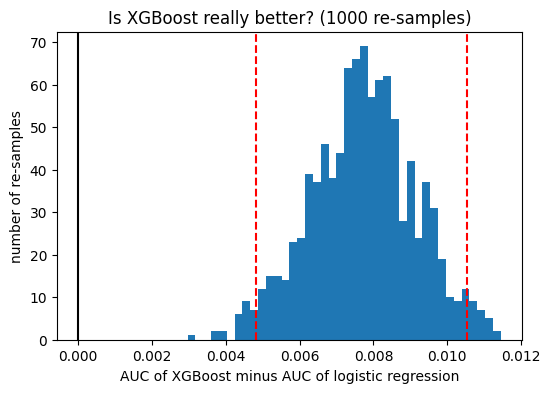

In [14]:
import numpy as np, pandas as pd, time
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

yv = y_te.astype(int)

# XGBoost predictions: reuse if still in memory, otherwise retrain (about 40 s)
try:
    p_xgb = preds["xgboost"]
except NameError:
    print("retraining XGBoost ...")
    xg = XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8,
                       colsample_bytree=0.8, min_child_weight=5, tree_method="hist",
                       n_jobs=-1, random_state=42, eval_metric="logloss").fit(Xt_tr, y_tr)
    p_xgb = xg.predict_proba(Xt_te)[:, 1]

models = {"LR": p_plain, "XGB": p_xgb, "weighted raw": p_raw, "weighted+Platt": p_platt,
          "weighted+shift": p_shift, "weighted+isotonic": p_iso}
if "p_lr_ng" in globals() and "p_xgb_ng" in globals():
    models["LR no gender"] = p_lr_ng
    models["XGB no gender"] = p_xgb_ng
models = {k: np.clip(np.asarray(v, dtype=float), 1e-6, 1 - 1e-6) for k, v in models.items()}
names = list(models)
cols = ["AUC", "log-loss", "Brier", "ECE"]

def metrics(p, yy):
    ll = -np.mean(yy * np.log(p) + (1 - yy) * np.log(1 - p))
    return np.array([roc_auc_score(yy, p), ll, np.mean((p - yy) ** 2), ece_quantile(yy, p)])

# gender masks, if they exist from the earlier cell
have_gender = "mF" in globals() and "mM" in globals()
gap_names = [k for k in ["LR", "XGB", "LR no gender", "XGB no gender"] if k in models] if have_gender else []

B = 1000
rng = np.random.default_rng(42)
n = len(yv)
res = {k: np.zeros((B, 4)) for k in names}
gap = {k: np.zeros((B, 2)) for k in gap_names}

t0 = time.time()
for b in range(B):
    idx = rng.integers(0, n, n)          # a redrawn test group, with repeats
    yy = yv[idx]
    for k in names:
        res[k][b] = metrics(models[k][idx], yy)
    for k in gap_names:
        p = models[k][idx]
        for j, m in enumerate((mF[idx], mM[idx])):
            gap[k][b, j] = p[m].mean() - yy[m].mean()
    if (b + 1) % 200 == 0:
        print(f"{b + 1} of {B} re-samples done, {round(time.time() - t0)} s")

# ---- 1. each model's scores with 95% intervals ----
full = {k: metrics(models[k], yv) for k in names}
rows = []
for k in names:
    lo, hi = np.percentile(res[k], [2.5, 97.5], axis=0)
    rows.append([k] + [f"{full[k][j]:.4f} [{lo[j]:.4f}, {hi[j]:.4f}]" for j in range(4)])
summary = pd.DataFrame(rows, columns=["model"] + cols)
print("\nTEST SCORES WITH 95% INTERVALS")
print(summary.to_string(index=False))
summary.to_csv("bootstrap_summary.csv", index=False)

# ---- 2. paired comparisons ----
pairs = [("XGB", "LR", 0), ("XGB", "LR", 1), ("LR no gender", "LR", 0), ("XGB no gender", "XGB", 0),
         ("weighted+Platt", "weighted+shift", 1), ("weighted+Platt", "weighted+shift", 3),
         ("weighted+isotonic", "weighted+Platt", 1), ("weighted+isotonic", "weighted+Platt", 3)]
rows = []
for a, b_, j in pairs:
    if a in models and b_ in models:
        d = res[a][:, j] - res[b_][:, j]
        lo, hi = np.percentile(d, [2.5, 97.5])
        est = full[a][j] - full[b_][j]
        rows.append([f"{a} minus {b_}", cols[j], round(est, 5), round(lo, 5), round(hi, 5),
                     "real" if (lo > 0 or hi < 0) else "cannot tell"])
print("\nPAIRED COMPARISONS (first model minus second)")
print(pd.DataFrame(rows, columns=["comparison", "metric", "difference", "CI low", "CI high", "verdict"]).to_string(index=False))

# ---- 3. gender gaps: mean predicted minus observed, in percentage points ----
if gap_names:
    rows = []
    for k in gap_names:
        for j, (g, m) in enumerate([("women", mF), ("men", mM)]):
            est = (models[k][m].mean() - yv[m].mean()) * 100
            lo, hi = np.percentile(gap[k][:, j], [2.5, 97.5]) * 100
            rows.append([k, g, round(est, 3), round(lo, 3), round(hi, 3),
                         "real gap" if (lo > 0 or hi < 0) else "within luck"])
    print("\nGENDER GAPS (predicted minus observed default rate, percentage points)")
    print(pd.DataFrame(rows, columns=["model", "group", "gap", "CI low", "CI high", "verdict"]).to_string(index=False))

# ---- 4. how big would ECE be from luck alone? ----
sim = [ece_quantile((rng.random(n) < models["LR"]).astype(int), models["LR"]) for _ in range(200)]
print("\nECE of a perfectly calibrated model on this many people: mean",
      round(float(np.mean(sim)), 4), " 95th percentile", round(float(np.percentile(sim, 95)), 4))

# ---- picture ----
d = res["XGB"][:, 0] - res["LR"][:, 0]
lo, hi = np.percentile(d, [2.5, 97.5])
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(d, bins=40)
ax.axvline(0, color="k"); ax.axvline(lo, color="r", ls="--"); ax.axvline(hi, color="r", ls="--")
ax.set_xlabel("AUC of XGBoost minus AUC of logistic regression"); ax.set_ylabel("number of re-samples")
ax.set_title("Is XGBoost really better? (1000 re-samples)")
plt.savefig("bootstrap_auc_diff.png", dpi=150, bbox_inches="tight"); plt.show()

In [ ]:
import numpy as np, pandas as pd, time, xgboost as xgbmod
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from logreg import fit_newton

try:
    cat_cols
except NameError:
    cat_cols = (pd.read_parquet("clean.parquet").drop(columns=["TARGET", "SK_ID_CURR"])
                .select_dtypes(exclude="number").columns.tolist())

fn = list(feat_names)
def variable_of(f):
    if f.startswith("num__"):
        return f[5:]
    body = f[5:]
    return max((c for c in cat_cols if body.startswith(c + "_")), key=len)
var_of = np.array([variable_of(f) for f in fn])
variables = sorted(set(var_of))
groups_idx = {v: np.where(var_of == v)[0] for v in variables}

idx_te = np.random.RandomState(0).choice(len(Xt_te), 3000, replace=False)
dte = xgbmod.DMatrix(Xt_te[idx_te])

B = 15
rng = np.random.default_rng(7)
n = len(y_tr)
i_cr, i_gp = fn.index("num__AMT_CREDIT"), fn.index("num__AMT_GOODS_PRICE")
shap_imp = np.zeros((B, len(variables)))
lr_coef = np.zeros((B, 3))
t0 = time.time()
for b in range(B):
    counts = np.bincount(rng.integers(0, n, n), minlength=n).astype(float)   # a redrawn training group, as weights
    th, _ = fit_newton(A, y, sample_weight=counts, penalty=pen, theta0=theta_plain, max_iter=30, tol=1e-7)
    lr_coef[b] = [th[i_cr], th[i_gp], th[i_cr] + th[i_gp]]
    m = XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                      min_child_weight=5, tree_method="hist", n_jobs=-1, random_state=b, eval_metric="logloss")
    m.fit(Xt_tr, y_tr, sample_weight=counts)
    contrib = m.get_booster().predict(dte, pred_contribs=True)[:, :-1]
    for j, v in enumerate(variables):
        shap_imp[b, j] = np.abs(contrib[:, groups_idx[v]].sum(axis=1)).mean()
    print(f"resample {b + 1} of {B} done, {round(time.time() - t0)} s")

ranks = (-shap_imp).argsort(axis=1).argsort(axis=1) + 1      # rank 1 = most important in that resample
mean_imp = shap_imp.mean(axis=0)
order = np.argsort(-mean_imp)[:12]
rows = [[variables[j], round(mean_imp[j], 4), int(np.median(ranks[:, j])),
         f"{ranks[:, j].min()} to {ranks[:, j].max()}", f"{(ranks[:, j] <= 5).mean() * 100:.0f}%"] for j in order]
print("\nXGBOOST EXPLANATION STABILITY (mean |SHAP| per variable, 15 re-samples of the training group)")
print(pd.DataFrame(rows, columns=["variable", "mean |SHAP|", "median rank", "rank range", "in top 5"]).to_string(index=False))

print("\nLOGISTIC REGRESSION COEFFICIENTS ACROSS RE-SAMPLES (features are standardised)")
print(pd.DataFrame(lr_coef, columns=["AMT_CREDIT", "AMT_GOODS_PRICE", "sum of the two"])
      .describe().loc[["mean", "std", "min", "max"]].round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
top = order[:8]
ax[0].boxplot([ranks[:, j] for j in top], vert=False)
ax[0].set_yticklabels([variables[j][:16] for j in top])
ax[0].invert_yaxis(); ax[0].set_xlabel("rank (1 = most important)"); ax[0].set_title("SHAP ranking across re-samples")
ax[1].scatter(lr_coef[:, 0], lr_coef[:, 1])
ax[1].set_xlabel("AMT_CREDIT coefficient"); ax[1].set_ylabel("AMT_GOODS_PRICE coefficient")
ax[1].set_title("Two collinear coefficients")
plt.tight_layout(); plt.savefig("explanation_stability.png", dpi=150, bbox_inches="tight"); plt.show()

resample 1 of 15 done, 20 s
resample 2 of 15 done, 46 s
resample 3 of 15 done, 70 s
resample 4 of 15 done, 90 s
resample 5 of 15 done, 110 s
resample 6 of 15 done, 135 s
resample 7 of 15 done, 160 s
resample 8 of 15 done, 179 s
resample 9 of 15 done, 199 s
resample 10 of 15 done, 225 s
resample 11 of 15 done, 251 s
